# H-1B Labor Condition Applications, FY2023: an open-ended exploration

This notebook explores the **Labor Condition Application (LCA) disclosure data** published by the
U.S. Department of Labor (DOL) for fiscal year 2023 (1 October 2022 – 30 September 2023).

**What an LCA is.** Before an employer can petition USCIS for an H-1B worker, it must file an LCA with
DOL attesting that it will pay at least the *prevailing wage* for the occupation and location. DOL
checks the form for completeness and obvious errors, not the merits. That shapes how to read the data:

* An LCA is **not** an H-1B visa or approval. It is an early step in the process. One LCA can cover several
  workers, one worker can have several LCAs, and many certified LCAs are never used.
* Counts here measure **employer demand and intent**, not visas issued.
* "Wage" means the **offered wage** written on the form, not what the worker was eventually paid.

There is no single question here. The sections move from data quality, to who files, for what jobs,
where, at what pay, and how employer business models differ.

| Section | Theme |
|---|---|
| 1 | Setup and loading |
| 2 | Data quality: duplicated cases across quarterly files |
| 3 | Case outcomes and processing time |
| 4 | Timing: when LCAs are decided and when jobs start |
| 5 | Employers: how concentrated is demand? |
| 6 | Occupations and industries |
| 7 | Geography |
| 8 | Wages: offered pay vs. the legal floor |
| 9 | Two business models: H-1B-dependent employers vs. everyone else |
| 10 | Why the LCA was filed: new hires, extensions, transfers |
| 11 | The smaller visa classes: E-3 and H-1B1 |
| 12 | Summary of findings and caveats |

## 1. Setup and loading

In [1]:
# Standard scientific stack. Loading/cleaning lives in lca.py (same folder),
# so this notebook can focus on the analysis.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

import lca

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)

In [2]:
# A small, consistent chart style: thin marks, light grid, no top/right spines.
# One fixed categorical order is used everywhere so a colour always means the same thing.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GREY = "#8a8984"
# Ordinal blue ramp (light -> dark) for the four prevailing-wage levels I-IV.
LEVEL_COLORS = {"I": "#86b6ef", "II": "#3987e5", "III": "#256abf", "IV": "#0d366b"}

plt.rcParams.update({
    "figure.figsize": (10, 4.5),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})

# Formatters reused by several charts.
dollars_k = mtick.FuncFormatter(lambda x, _: f"${x/1000:,.0f}k")
thousands = mtick.FuncFormatter(lambda x, _: f"{x/1000:,.0f}k" if x >= 1000 else f"{x:,.0f}")
pct = mtick.PercentFormatter(decimals=0)


def pretty(name: str, width: int = 34) -> str:
    # Readable chart label for an upper-cased employer name: title case, legal suffixes dropped.
    short = name.title()
    for suffix in [", Inc.", " Inc.", " Inc", " Llc", " Llp", " Limited", " Corporation", " Corp", ", N.A."]:
        short = short.replace(suffix, "")
    return short.rstrip(" ,")[:width]

The raw data are four quarterly Excel files in `data/`. `lca.load_raw()` stacks them (caching each as
Parquet on first run, since parsing ~240 MB of Excel takes a few minutes). Before cleaning anything, look at
what came in.

In [3]:
raw = lca.load_raw()
print(f"Rows: {len(raw):,}   Columns: {raw.shape[1]}")
print(f"Distinct case numbers: {raw['CASE_NUMBER'].nunique():,}")
raw.groupby("SOURCE_QUARTER").size().rename("rows per file").to_frame()

Rows: 644,607   Columns: 56
Distinct case numbers: 543,580


,rows per file
SOURCE_QUARTER,
1,98735
2,231544
3,186389
4,127939


## 2. Data quality: the quarterly files overlap

There are noticeably fewer distinct case numbers than rows, so some cases appear in more than one file.
If the files are simply stacked (as the original R script did), those cases get counted twice.
Which files do the duplicates come from, and do the copies differ?

In [4]:
dupes = raw[raw["CASE_NUMBER"].duplicated(keep=False)]

# For each duplicated case, the sequence of files it appears in, e.g. "12" = Q1 and Q2.
file_pattern = (dupes.groupby("CASE_NUMBER")["SOURCE_QUARTER"]
                     .agg(lambda s: "".join(map(str, sorted(s)))))
print(f"{dupes['CASE_NUMBER'].nunique():,} cases appear more than once ({len(dupes):,} rows)\n")
print("Files each duplicated case appears in:")
print(file_pattern.value_counts().head(6).to_string())

# How many duplicate rows are byte-for-byte identical apart from the file tag?
identical = dupes.drop(columns="SOURCE_QUARTER").duplicated(keep=False).mean()
print(f"\nShare of duplicate rows identical to another copy: {identical:.1%}")

100,197 cases appear more than once (201,224 rows)

Files each duplicated case appears in:
SOURCE_QUARTER
12     97905
23       867
24       595
124      427
123      403

Share of duplicate rows identical to another copy: 97.4%


In [5]:
# Where copies do differ, it is almost always the case status being updated.
status_path = (dupes.sort_values("SOURCE_QUARTER")
                    .groupby("CASE_NUMBER")["CASE_STATUS"]
                    .agg(" -> ".join))
status_path.value_counts().head(6).to_frame("cases")

,cases
CASE_STATUS,
Certified -> Certified,86457
Certified - Withdrawn -> Certified - Withdrawn,8475
Certified -> Certified - Withdrawn,2196
Withdrawn -> Withdrawn,1847
Certified -> Certified -> Certified - Withdrawn,830
Denied -> Denied,392


**Finding.** Nearly all duplicates are cases decided in Q1 that are *re-published in the Q2 file*.
The copies are identical apart from occasional status updates (e.g. a certified LCA later withdrawn).
Stacking the four files therefore over-counts by roughly 100,000 cases (~18%).

`lca.deduplicate()` keeps each case's **latest** appearance so its status is current. Everything below uses
the de-duplicated, cleaned table.

In [6]:
df = lca.load_lca()  # = clean(deduplicate(load_raw()))
del raw, dupes       # free memory; the raw stack is no longer needed
print(f"De-duplicated cases: {len(df):,}")
print(f"Decision dates: {df['DECISION_DATE'].min():%d %b %Y} to {df['DECISION_DATE'].max():%d %b %Y}")

De-duplicated cases: 543,580
Decision dates: 01 Oct 2022 to 30 Sep 2023


## 3. Case outcomes and processing time

The file covers four visa classes that share the LCA process: **H-1B** (the vast majority), **E-3**
(Australians), and **H-1B1** (Chileans and Singaporeans, under free-trade agreements).

In [7]:
outcomes = pd.crosstab(df["VISA_CLASS"], df["CASE_STATUS"], margins=True, margins_name="Total")
outcomes

CASE_STATUS,Certified,Certified - Withdrawn,Denied,Withdrawn,Total
VISA_CLASS,,,,,
E-3 Australian,9058,722,272,235,10287
H-1B,485508,32504,2249,9215,529476
H-1B1 Chile,1989,141,83,50,2263
H-1B1 Singapore,1391,115,20,28,1554
Total,497946,33482,2624,9528,543580


In [8]:
# Same table as row percentages. Status rates per visa class are easier to compare this way.
(pd.crosstab(df["VISA_CLASS"], df["CASE_STATUS"], normalize="index") * 100).round(2)

CASE_STATUS,Certified,Certified - Withdrawn,Denied,Withdrawn
VISA_CLASS,,,,
E-3 Australian,88.05,7.02,2.64,2.28
H-1B,91.70,6.14,0.42,1.74
H-1B1 Chile,87.89,6.23,3.67,2.21
H-1B1 Singapore,89.51,7.40,1.29,1.80


Denials are rare for H-1B (well under 1%). DOL only screens the form, so a denial usually means an
incomplete or inconsistent application rather than a judgement on the job. The smaller visa classes are
denied at several times the H-1B rate, plausibly because their filers are less practised with the form.

**"Certified - Withdrawn"** is a different kind of record: a case certified earlier and withdrawn by the employer
this year. Its receipt dates go back as far as 2019, so it mostly describes *older* filings. Processing
time makes that clear:

In [9]:
df.groupby("CASE_STATUS")["PROCESSING_DAYS"].describe()[["count", "min", "50%", "max"]]

,count,min,50%,max
CASE_STATUS,,,,
Certified,"497,946.00",5.00,7.00,10.00
Certified - Withdrawn,"33,482.00",5.00,377.00,"1,394.00"
Denied,"2,624.00",0.00,2.00,7.00
Withdrawn,"9,528.00",0.00,0.00,8.00


Certified cases are decided in a very tight window: median 7 calendar days, never more than 10. This fits the
statutory 7-working-day review for LCAs, and suggests a largely automated check. Denials come within a week,
and withdrawals are usually same-day (the employer pulls the form almost as soon as it is filed).

**Analysis universe from here on.** Unless stated otherwise, the rest of the notebook uses
**H-1B cases with status "Certified"**: current-year approvals, with no withdrawn or prior-year records.

In [10]:
h1b = df[(df["VISA_CLASS"] == "H-1B") & (df["CASE_STATUS"] == "Certified")].copy()
print(f"Certified H-1B LCAs: {len(h1b):,}")
print(f"Worker positions they cover: {h1b['TOTAL_WORKER_POSITIONS'].sum():,.0f}")
print(f"Share of LCAs covering exactly one position: {(h1b['TOTAL_WORKER_POSITIONS'] == 1).mean():.1%}")

Certified H-1B LCAs: 485,508
Worker positions they cover: 898,747
Share of LCAs covering exactly one position: 94.7%


Most LCAs cover one worker. A small number of multi-position filings (up to several hundred positions) roughly
double the total "positions" count. Positions are an upper bound on intent, not a headcount, so the rest of the
notebook counts **LCAs** rather than positions.

## 4. Timing: when LCAs are decided and when jobs start

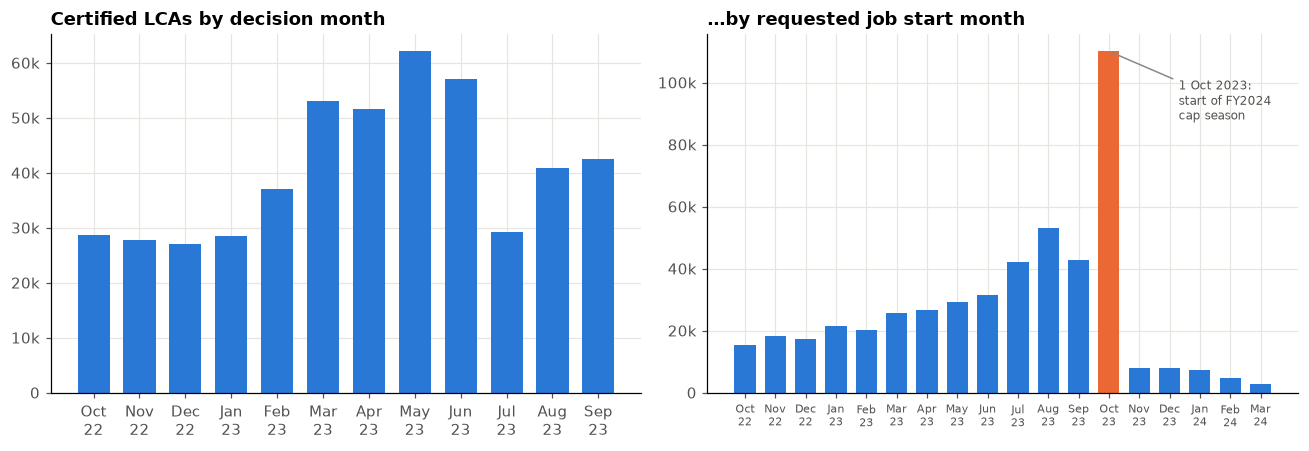

Share of all certified LCAs with a job start in October 2023: 22.7%


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

# Left: decisions per month across the fiscal year.
by_decision = h1b["DECISION_DATE"].dt.to_period("M").value_counts().sort_index()
axes[0].bar(by_decision.index.strftime("%b\n%y"), by_decision.values, color=BLUE, width=0.7)
axes[0].set_title("Certified LCAs by decision month")
axes[0].yaxis.set_major_formatter(thousands)

# Right: requested employment start month (limit to the window where nearly all fall).
begin = h1b["BEGIN_DATE"].dt.to_period("M")
by_begin = begin[(begin >= "2022-10") & (begin <= "2024-03")].value_counts().sort_index()
colors = [ORANGE if p == pd.Period("2023-10") else BLUE for p in by_begin.index]
axes[1].bar(by_begin.index.strftime("%b\n%y"), by_begin.values, color=colors, width=0.7)
axes[1].set_title("…by requested job start month")
axes[1].yaxis.set_major_formatter(thousands)
axes[1].tick_params(axis="x", labelsize=7)
axes[1].annotate("1 Oct 2023:\nstart of FY2024\ncap season", xy=(12, by_begin.iloc[12]),
                 xytext=(14.3, by_begin.iloc[12] * 0.8), fontsize=8, color="#52514e",
                 arrowprops=dict(arrowstyle="-", color=GREY))
plt.tight_layout()
plt.show()

oct_share = (h1b["BEGIN_DATE"].dt.to_period("M") == "2023-10").mean()
print(f"Share of all certified LCAs with a job start in October 2023: {oct_share:.1%}")

Two rhythms show up:

* **Decisions peak in March–June.** This is the run-up to and aftermath of the H-1B cap lottery
  (registration in March, petitions from April). Employers need a certified LCA before they can file a petition.
* **Start dates spike on 1 October 2023.** New cap-subject H-1B workers cannot start before the first day of
  the next fiscal year, so lottery winners' LCAs all request that date. More than a fifth of all certified LCAs
  in FY2023 target that single day.
* **July is a trough in decisions**, between the spring lottery wave and a late-summer pick-up.

## 5. Employers: how concentrated is demand?

In [12]:
per_employer = h1b["EMPLOYER"].value_counts()
n_emp = len(per_employer)
top10 = per_employer.head(10).sum() / per_employer.sum()
top1pct = per_employer.head(max(1, n_emp // 100)).sum() / per_employer.sum()
single = (per_employer == 1).mean()

print(f"Distinct employers (by cleaned name):   {n_emp:,}")
print(f"Share of LCAs from the top 10 employers: {top10:.1%}")
print(f"Share of LCAs from the top 1% of employers ({n_emp // 100:,} firms): {top1pct:.1%}")
print(f"Share of employers that filed exactly one LCA: {single:.1%}")

Distinct employers (by cleaned name):   54,159
Share of LCAs from the top 10 employers: 16.7%
Share of LCAs from the top 1% of employers (541 firms): 49.7%
Share of employers that filed exactly one LCA: 50.7%


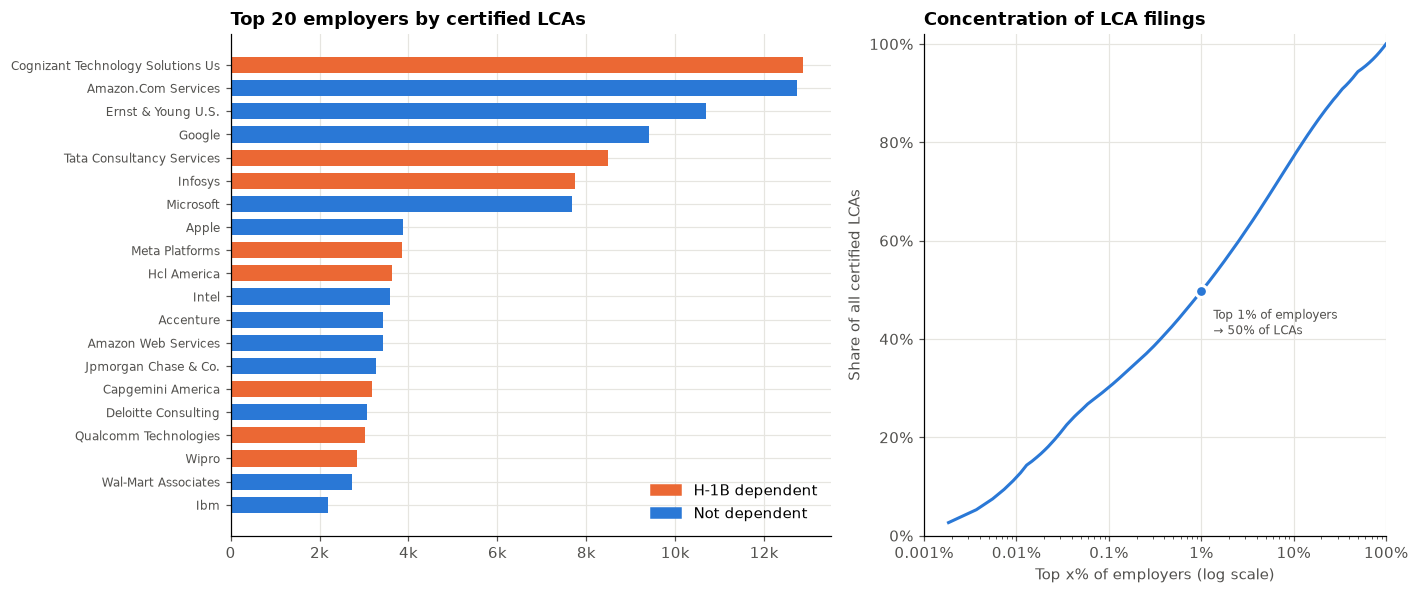

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})

# Left: top 20 employers. Colour marks whether the employer reports itself as H-1B dependent
# (see section 9). That is the most useful single split of these firms.
top20 = per_employer.head(20)[::-1]
dependent = h1b.groupby("EMPLOYER")["H_1B_DEPENDENT"].agg(lambda s: (s == "Yes").mean() > 0.5)
bar_colors = [ORANGE if dependent[e] else BLUE for e in top20.index]
axes[0].barh([pretty(e) for e in top20.index], top20.values, color=bar_colors, height=0.7)
axes[0].set_title("Top 20 employers by certified LCAs")
axes[0].xaxis.set_major_formatter(thousands)
axes[0].tick_params(axis="y", labelsize=8)
axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ORANGE), plt.Rectangle((0, 0), 1, 1, color=BLUE)],
               labels=["H-1B dependent", "Not dependent"], loc="lower right", frameon=False)

# Right: Lorenz-style curve. x = employers ranked largest first, y = cumulative share of LCAs.
cum_share = per_employer.cumsum() / per_employer.sum()
emp_share = np.arange(1, n_emp + 1) / n_emp
axes[1].plot(emp_share * 100, cum_share.values * 100, color=BLUE, lw=2)
# Mark the "top 1% of employers" point quoted above.
axes[1].scatter([1], [top1pct * 100], s=60, color=BLUE, edgecolor="white", linewidth=2, zorder=3)
axes[1].annotate(f"Top 1% of employers\n→ {top1pct:.0%} of LCAs", (1, top1pct * 100), xytext=(8, -28),
                 textcoords="offset points", fontsize=8, color="#52514e")
axes[1].set_xscale("log")
axes[1].set_xlim(0.001, 100)
axes[1].set_ylim(0, 102)
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:g}%"))
axes[1].yaxis.set_major_formatter(pct)
axes[1].set_xlabel("Top x% of employers (log scale)")
axes[1].set_ylabel("Share of all certified LCAs")
axes[1].set_title("Concentration of LCA filings")
plt.tight_layout()
plt.show()

Demand is **both concentrated and long-tailed**. About 540 large filers (the top 1%) account for half
of all certified LCAs. Meanwhile about half of the ~54,000 employers filed exactly one, the typical
small-business H-1B sponsor. The top 20 mixes big tech (Amazon, Google, Microsoft, Apple, Meta), the Big Four and
consultancies (EY, Deloitte, Accenture), banks, and Indian-headquartered IT services firms
(Cognizant, TCS, Infosys, HCL, Wipro).

*Caveat:* names are only lightly normalised, so one company's legal entities count separately
(e.g. Amazon.com Services, Amazon Web Services and Amazon Development Center).

## 6. Occupations and industries

Distinct SOC occupations: 849
Share in 'Computer and Mathematical' occupations (SOC 15-xxxx): 66.4%
Share that are 'Software Developers' alone: 34.9%


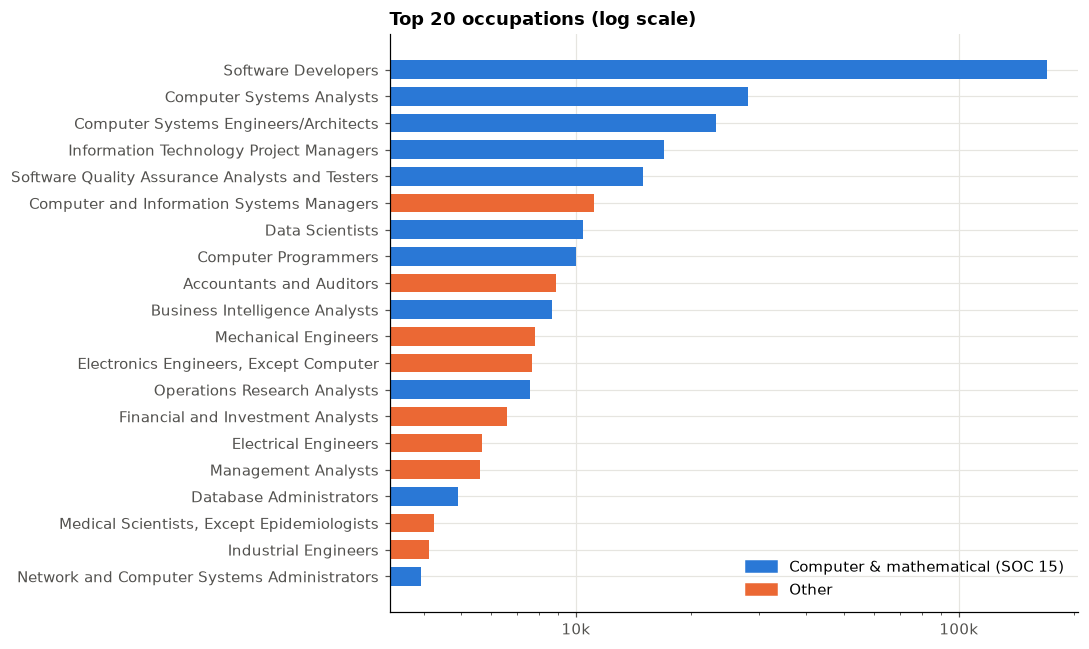

In [14]:
soc = h1b["SOC_TITLE"].value_counts()
computer_share = (h1b["SOC_MAJOR"] == "15").mean()
print(f"Distinct SOC occupations: {len(soc):,}")
print(f"Share in 'Computer and Mathematical' occupations (SOC 15-xxxx): {computer_share:.1%}")
print(f"Share that are 'Software Developers' alone: {soc.iloc[0] / soc.sum():.1%}")

fig, ax = plt.subplots(figsize=(10, 6))
top_soc = soc.head(20)[::-1]
colors = [BLUE if code_.startswith("15") else ORANGE
          for code_ in h1b.groupby("SOC_TITLE")["SOC_MAJOR"].first()[top_soc.index]]
ax.barh(top_soc.index, top_soc.values, color=colors, height=0.7)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(thousands)
ax.set_title("Top 20 occupations (log scale)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=ORANGE)],
          labels=["Computer & mathematical (SOC 15)", "Other"], loc="lower right", frameon=False)
plt.tight_layout()
plt.show()

The H-1B programme, as seen through LCAs, is overwhelmingly a **tech programme**: two in three certified LCAs are for
computer and mathematical occupations, and "Software Developers" alone is about a third. The log scale hides how
steep the drop is. Software developers outnumber the second occupation, computer systems analysts, roughly six to one. Accountants,
mechanical/electrical engineers and financial analysts are the main non-computing occupations.

Industry (NAICS sector of the *employer*) tells a related but different story:

In [15]:
# Short labels for the NAICS sectors that matter here; the long tail is grouped as "Other".
NAICS_LABELS = {
    "54": "Professional, scientific & technical services",
    "31": "Manufacturing", "32": "Manufacturing", "33": "Manufacturing",
    "51": "Information (software, media, telecom)",
    "52": "Finance & insurance",
    "61": "Educational services (universities)",
    "44": "Retail trade", "45": "Retail trade",
    "62": "Health care",
}
h1b["SECTOR"] = h1b["NAICS_SECTOR"].map(NAICS_LABELS).fillna("Other")

sector = (h1b.groupby("SECTOR")
              .agg(lcas=("CASE_NUMBER", "size"), median_wage=("ANNUAL_WAGE", "median"))
              .sort_values("lcas", ascending=False))
sector["share"] = sector["lcas"] / sector["lcas"].sum()
sector.style.format({"lcas": "{:,}", "median_wage": "${:,.0f}", "share": "{:.1%}"})

,lcas,median_wage,share
SECTOR,,,
"Professional, scientific & technical services","253,489","$101,421",52.2%
Manufacturing,"49,108","$121,597",10.1%
"Information (software, media, telecom)","40,307","$148,400",8.3%
Finance & insurance,"38,343","$130,000",7.9%
Educational services (universities),"31,078","$70,000",6.4%
Other,"27,785","$110,000",5.7%
Retail trade,"25,657","$140,000",5.3%
Health care,"19,741","$101,504",4.1%


Over half of LCAs come from **professional, scientific and technical services**. That sector includes both the IT
consultancies and the Big Four, so many "software developers" are placed with clients rather than working
for the end user of their work. Retail at about 5% looks odd until you remember Amazon and Walmart file under it,
which is also why its median wage is so high.
**Universities** pay the lowest median of any major sector (about $70k). Universities, their affiliated
non-profits and research organisations are exempt from the annual H-1B cap, so they can hire postdocs and lecturers year-round.

## 7. Geography

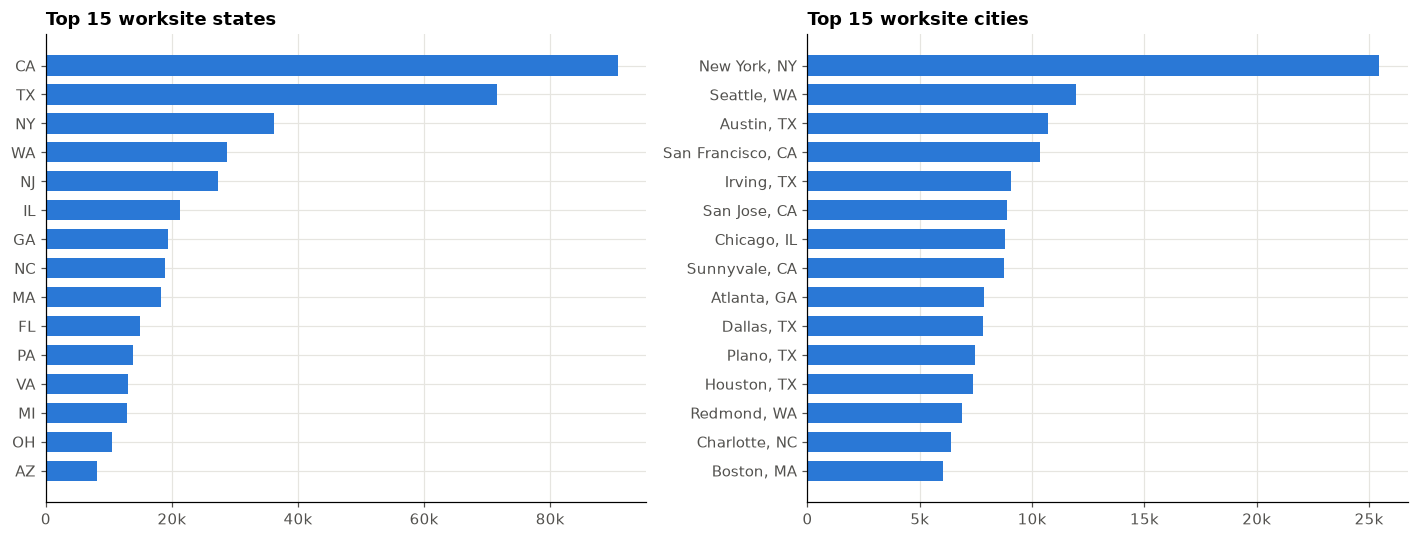

CA + TX share of all LCAs: 33.4%


In [16]:
state = h1b["WORKSITE_STATE"].value_counts()
city = (h1b["WORKSITE_CITY"] + ", " + h1b["WORKSITE_STATE"]).value_counts()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
top_states = state.head(15)[::-1]
axes[0].barh(top_states.index, top_states.values, color=BLUE, height=0.7)
axes[0].set_title("Top 15 worksite states")
axes[0].xaxis.set_major_formatter(thousands)

top_cities = city.head(15)[::-1]
axes[1].barh(top_cities.index, top_cities.values, color=BLUE, height=0.7)
axes[1].set_title("Top 15 worksite cities")
axes[1].xaxis.set_major_formatter(thousands)
plt.tight_layout()
plt.show()

print(f"CA + TX share of all LCAs: {(state['CA'] + state['TX']) / state.sum():.1%}")

California and Texas together host a third of all worksites. The city list adds detail the state view misses:

* **Texas is a hub for IT services.** Irving and Plano are home to the US headquarters or delivery centres of
  several large outsourcing firms, so they rank alongside Austin and Dallas.
* **Big tech campuses stand out as cities:** Seattle and Redmond (Amazon, Microsoft), Sunnyvale and San Jose
  (Google, Apple, chip firms).
* **New York City** is the single largest worksite city, driven by finance and consulting.

Same occupation, different place: how much does a software developer's offered wage vary by state?

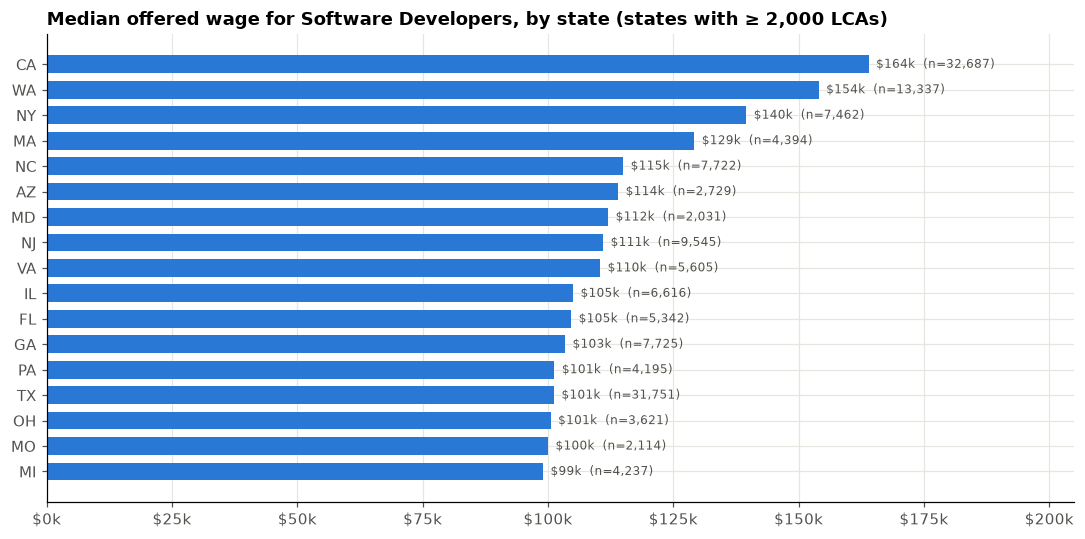

In [17]:
sd = h1b[h1b["SOC_TITLE"] == "Software Developers"]
sd_state = (sd.groupby("WORKSITE_STATE")["ANNUAL_WAGE"]
              .agg(lcas="size", median="median")
              .query("lcas >= 2000")          # only states with a large sample
              .sort_values("median"))

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(sd_state.index, sd_state["median"], color=BLUE, height=0.7)
for y, (v, n) in enumerate(zip(sd_state["median"], sd_state["lcas"])):
    ax.text(v + 1500, y, f"${v/1000:,.0f}k  (n={n:,})", va="center", fontsize=8, color="#52514e")
ax.xaxis.set_major_formatter(dollars_k)
ax.set_xlim(0, sd_state["median"].max() * 1.25)
ax.set_title("Median offered wage for Software Developers, by state (states with ≥ 2,000 LCAs)")
plt.tight_layout()
plt.show()

For the *same SOC occupation* the median offer ranges from about \$99k (Michigan) to \$164k (California), a
**65% spread**. Some of that is cost of living, since prevailing wages are set per metro area. Some is employer mix:
California and Washington are dominated by big-tech employers (section 9 shows they pay well above the floor),
while Texas, New Jersey and the Midwest have far more IT-services filings.

## 8. Wages: offered pay vs. the legal floor

Every LCA states two numbers: the **offered wage** and the **prevailing wage (PW)**, the legal minimum for that
occupation, location and *experience level*. DOL defines four PW levels, from Level I (entry) to Level IV (fully
competent). The employer chooses the level when it classifies the job. Employers may also use a private salary
survey or a union agreement instead of DOL's default (OES) figures.

`lca.annualize_wages()` puts both on an annual basis. About 140 certified H-1B filings (≈200 across all cases) typed an
annual salary but picked "Hour" or another sub-annual unit, which would otherwise produce "wages" in the hundreds of millions. These are repaired
conservatively (see the docstring in `lca.py`).

In [18]:
print(f"Wage-unit entries repaired: {h1b['WAGE_UNIT_FIXED'].sum():,}")
print(f"Offered wages below the prevailing wage: {(h1b['WAGE_TO_PW'] < 0.999).sum():,}\n")

pctl = h1b["ANNUAL_WAGE"].quantile([0.01, 0.10, 0.25, 0.50, 0.75, 0.90, 0.99])
pctl.index = [f"p{int(q * 100)}" for q in pctl.index]
pctl.to_frame("annual offered wage").style.format("${:,.0f}")

Wage-unit entries repaired: 143
Offered wages below the prevailing wage: 2



,annual offered wage
p1,"$47,476"
p10,"$71,000"
p25,"$87,173"
p50,"$110,000"
p75,"$142,800"
p90,"$181,500"
p99,"$289,000"


As expected, essentially no certified LCA offers less than the prevailing wage (DOL rejects those), so the floor
holds mechanically. The median offer is **\$110k**, and the middle half of offers sits between about \$87k and \$143k.
A thin tail of very high values remains (some real, e.g. physicians; some probably still entry errors), so the
analysis relies on **medians**, which that tail does not move.

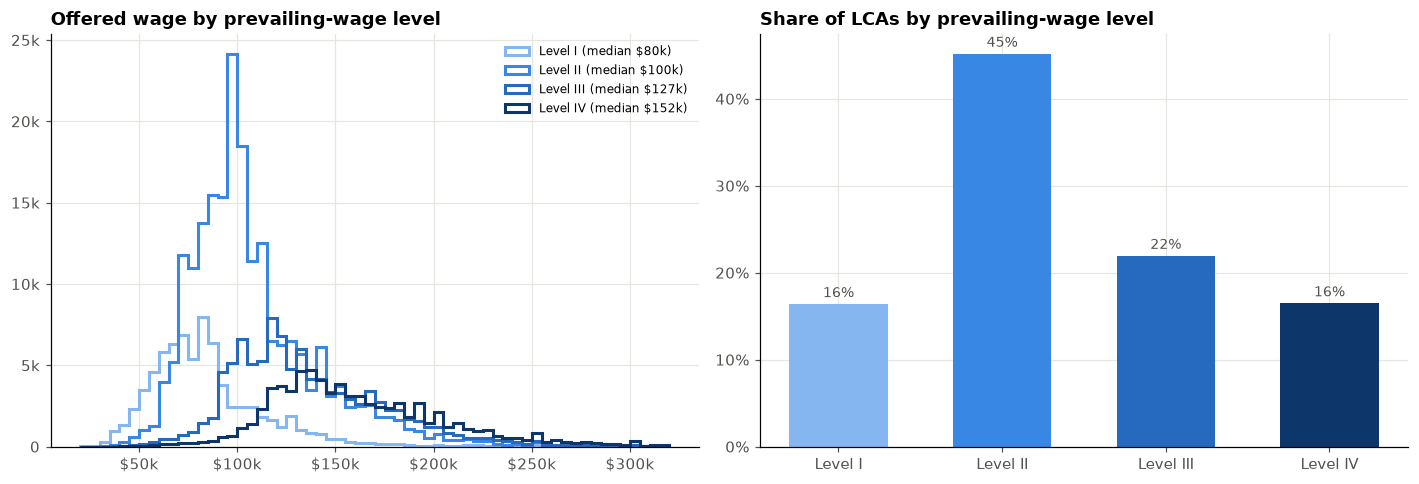

LCAs with no PW level (5.0%) use a private salary survey or union (CBA) wage instead.


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: offered wage distribution, split by PW level (overlaid step histograms keep each level visible).
bins = np.arange(20_000, 320_001, 5_000)
for level in ["I", "II", "III", "IV"]:
    vals = h1b.loc[h1b["PW_WAGE_LEVEL"] == level, "ANNUAL_WAGE"]
    axes[0].hist(vals, bins=bins, histtype="step", lw=2, color=LEVEL_COLORS[level],
                 label=f"Level {level} (median ${vals.median()/1000:,.0f}k)")
axes[0].xaxis.set_major_formatter(dollars_k)
axes[0].yaxis.set_major_formatter(thousands)
axes[0].set_title("Offered wage by prevailing-wage level")
axes[0].legend(frameon=False, fontsize=8)

# Right: share of LCAs at each level.
level_share = h1b["PW_WAGE_LEVEL"].value_counts(normalize=True).reindex(["I", "II", "III", "IV"])
axes[1].bar(["Level I", "Level II", "Level III", "Level IV"], level_share.values * 100,
            color=[LEVEL_COLORS[l] for l in level_share.index], width=0.6)
for x, v in enumerate(level_share.values):
    axes[1].text(x, v * 100 + 0.8, f"{v:.0%}", ha="center", fontsize=9, color="#52514e")
axes[1].yaxis.set_major_formatter(pct)
axes[1].set_title("Share of LCAs by prevailing-wage level")
plt.tight_layout()
plt.show()

missing_level = h1b["PW_WAGE_LEVEL"].isna().mean()
print(f"LCAs with no PW level ({missing_level:.1%}) use a private salary survey or union (CBA) wage instead.")

**Level II is the modal classification**, at 45% of LCAs, more than Levels I and IV combined. Medians rise steadily
with level (\$80k → \$100k → \$127k → \$152k), so the classification matters. Level I, the entry level, is the least
used despite H-1B being a common route for recent graduates.

How far above the floor do employers go? The ratio `offered wage / prevailing wage` measures it: 1.0 means paying
exactly the legal minimum.

Offered wage exactly at the prevailing wage: 36.8%
Median premium over prevailing wage:         5.1%
Share paying ≥ 25% above prevailing wage:    22.9%


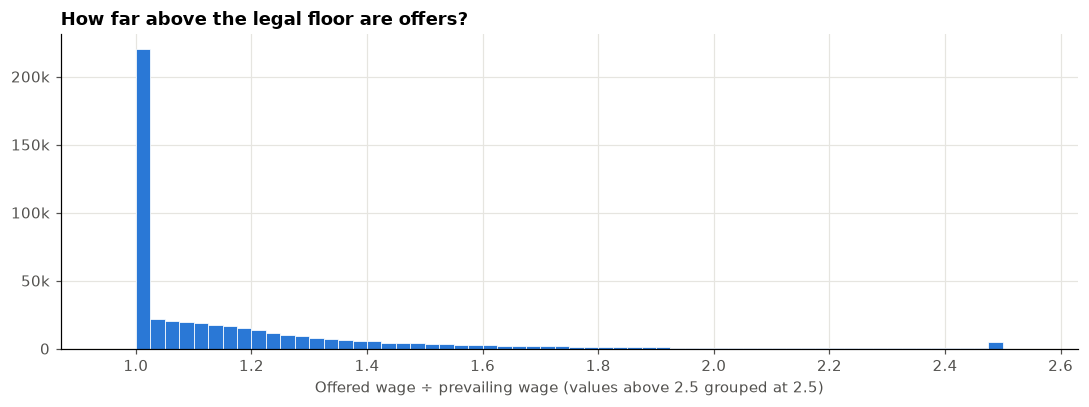

In [20]:
ratio = h1b["WAGE_TO_PW"]
at_floor = np.isclose(h1b["ANNUAL_WAGE"], h1b["ANNUAL_PW"], rtol=0.001)  # within 0.1% of PW

print(f"Offered wage exactly at the prevailing wage: {at_floor.mean():.1%}")
print(f"Median premium over prevailing wage:         {ratio.median() - 1:.1%}")
print(f"Share paying ≥ 25% above prevailing wage:    {(ratio >= 1.25).mean():.1%}")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hist(ratio.clip(upper=2.5), bins=np.arange(0.95, 2.551, 0.025), color=BLUE, edgecolor="white", linewidth=0.5)
ax.set_xlabel("Offered wage ÷ prevailing wage (values above 2.5 grouped at 2.5)")
ax.yaxis.set_major_formatter(thousands)
ax.set_title("How far above the legal floor are offers?")
plt.tight_layout()
plt.show()

The distribution has a **spike at exactly 1.0**: over a third of all certified LCAs list an offered wage identical to
the prevailing wage. The rest spreads out into a long right tail, and the median premium is a modest 5%.

Read that spike with care. "Offered = prevailing" means *the two numbers on the form are equal*, which can happen two ways:
the employer pays exactly the legal minimum, or the employer enters the job's own pay as the prevailing wage
(e.g. from its own salary survey). Section 9 shows both happen.

**Wage ranges.** About a third of LCAs give a range ("from–to") rather than a single number. Where they do, how wide is it?

In [21]:
ranged = h1b.dropna(subset=["ANNUAL_WAGE_TO"])
ranged = ranged[ranged["ANNUAL_WAGE_TO"] >= ranged["ANNUAL_WAGE"]]
width = ranged["ANNUAL_WAGE_TO"] / ranged["ANNUAL_WAGE"] - 1

print(f"LCAs with a wage range: {len(ranged):,} ({len(ranged) / len(h1b):.1%})")
print(f"Median width of the range (top ÷ bottom − 1): {width.median():.0%}\n")

# Which large employers post ranges, and on what share of their own filings?
range_by_emp = pd.DataFrame({
    "ranged_lcas": ranged["EMPLOYER"].value_counts(),
    "all_lcas": h1b["EMPLOYER"].value_counts(),
}).dropna().nlargest(8, "ranged_lcas")
range_by_emp["share_ranged"] = range_by_emp["ranged_lcas"] / range_by_emp["all_lcas"]
range_by_emp.style.format({"ranged_lcas": "{:,.0f}", "all_lcas": "{:,.0f}", "share_ranged": "{:.0%}"})

LCAs with a wage range: 158,907 (32.7%)
Median width of the range (top ÷ bottom − 1): 22%



,ranged_lcas,all_lcas,share_ranged
EMPLOYER,,,
TATA CONSULTANCY SERVICES LIMITED,"8,479","8,483",100%
INFOSYS LIMITED,"6,943","7,755",90%
INTEL CORPORATION,"3,576","3,576",100%
ACCENTURE LLP,"3,265","3,436",95%
"QUALCOMM TECHNOLOGIES, INC.","3,022","3,022",100%
CAPGEMINI AMERICA INC,"2,532","3,182",80%
APPLE INC.,"2,094","3,872",54%
"COMPUNNEL SOFTWARE GROUP, INC","1,945","1,966",99%


Ranges are a firm-level habit rather than an industry norm: several large filers (e.g. TCS, Intel, Qualcomm) put a range on
essentially every LCA, while others of similar size (Cognizant, Google, Amazon, EY) almost never do. The typical range is about 20% wide. The "from" wage used throughout this
notebook is therefore a conservative lower bound for those firms.

## 9. Two business models: H-1B-dependent employers vs. everyone else

An employer is **H-1B dependent** if H-1B workers make up a large share of its workforce (roughly 15% or more for
larger firms). Dependent employers carry extra attestations, e.g. not displacing US workers, unless the worker earns
\$60k+ or holds a relevant master's degree. The flag is self-reported on every LCA.

Section 5 hinted that the dependent firms are a distinct group. Comparing the two directly:

In [22]:
h1b["AT_FLOOR"] = at_floor
dep = h1b[h1b["H_1B_DEPENDENT"].notna()]

summary = dep.groupby("H_1B_DEPENDENT").agg(
    lcas=("CASE_NUMBER", "size"),
    employers=("EMPLOYER", "nunique"),
    median_wage=("ANNUAL_WAGE", "median"),
    median_premium=("WAGE_TO_PW", lambda s: s.median() - 1),
    share_at_floor=("AT_FLOOR", "mean"),
    share_software_dev=("SOC_TITLE", lambda s: (s == "Software Developers").mean()),
)
summary.style.format({"lcas": "{:,}", "employers": "{:,}", "median_wage": "${:,.0f}",
                      "median_premium": "{:.1%}", "share_at_floor": "{:.1%}", "share_software_dev": "{:.1%}"})

,lcas,employers,median_wage,median_premium,share_at_floor,share_software_dev
H_1B_DEPENDENT,,,,,,
No,"346,101","50,235","$119,524",9.8%,28.6%,32.1%
Yes,"139,407","4,995","$99,008",0.0%,57.1%,41.9%


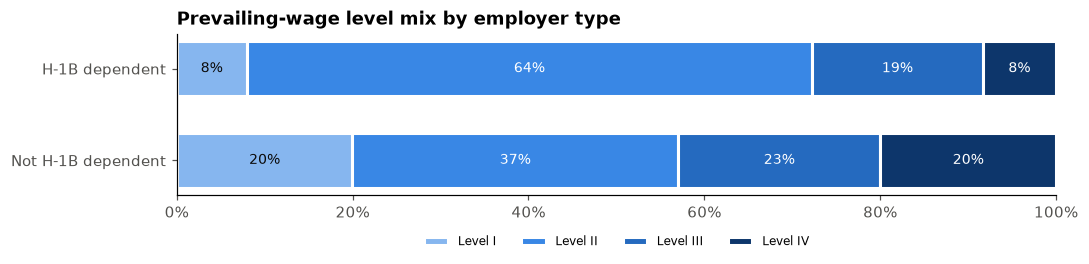

PW_WAGE_LEVEL,I,II,III,IV
H_1B_DEPENDENT,,,,
No,0.20,0.37,0.23,0.20
Yes,0.08,0.64,0.19,0.08


In [23]:
# PW-level mix for each group: rows sum to 100%.
level_mix = pd.crosstab(dep["H_1B_DEPENDENT"], dep["PW_WAGE_LEVEL"], normalize="index")[["I", "II", "III", "IV"]]

fig, ax = plt.subplots(figsize=(10, 2.6))
left = np.zeros(len(level_mix))
labels = {"No": "Not H-1B dependent", "Yes": "H-1B dependent"}
for level in ["I", "II", "III", "IV"]:
    vals = level_mix[level].values
    ax.barh([labels[i] for i in level_mix.index], vals, left=left, color=LEVEL_COLORS[level],
            edgecolor="white", linewidth=2, height=0.6, label=f"Level {level}")
    for y, (l, v) in enumerate(zip(left, vals)):
        if v > 0.06:
            ax.text(l + v / 2, y, f"{v:.0%}", ha="center", va="center", fontsize=9,
                    color="white" if level != "I" else "#0b0b0b")
    left += vals
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlim(0, 1)
ax.grid(False)
ax.legend(ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), fontsize=8)
ax.set_title("Prevailing-wage level mix by employer type")
plt.tight_layout()
plt.show()
level_mix.round(3)

The two groups look like different labour markets:

* Fewer than 10% of employers (about 5,000) describe themselves as dependent, yet they file about 29% of LCAs.
  The volume is concentrated in a handful of large IT services companies.
* They classify about **two thirds of their jobs at Level II**, versus 37% for everyone else, and use Levels I and IV much less.
  The result is a narrow, mid-low band.
* Their median premium over the prevailing wage is **zero**: 57% of their LCAs list exactly the prevailing wage, versus 29%
  for non-dependent employers. Their median offer is about \$20k lower.

This does *not* show anyone is underpaid relative to the law (every LCA meets the floor). It is consistent with the
staffing/outsourcing model of pricing to the floor, while many product companies pay a market premium on top.

The group averages hide a lot, though. The scatter below plots the 40 largest filers individually.

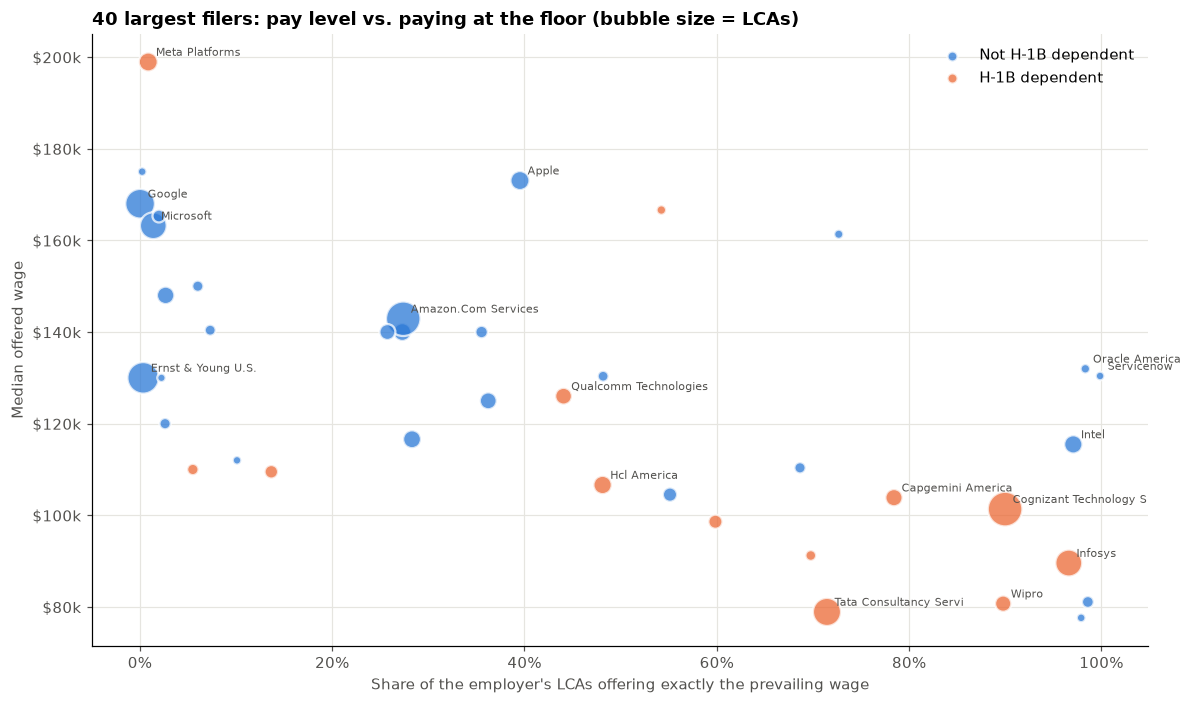

In [24]:
top40 = per_employer.head(40).index
emp_stats = (h1b[h1b["EMPLOYER"].isin(top40)]
             .groupby("EMPLOYER")
             .agg(lcas=("CASE_NUMBER", "size"),
                  median_wage=("ANNUAL_WAGE", "median"),
                  share_at_floor=("AT_FLOOR", "mean"),
                  dependent=("H_1B_DEPENDENT", lambda s: (s == "Yes").mean() > 0.5)))

fig, ax = plt.subplots(figsize=(11, 6.5))
for flag, color, label in [(False, BLUE, "Not H-1B dependent"), (True, ORANGE, "H-1B dependent")]:
    g = emp_stats[emp_stats["dependent"] == flag]
    ax.scatter(g["share_at_floor"] * 100, g["median_wage"], s=g["lcas"] / 25, color=color, alpha=0.75,
               edgecolor="white", linewidth=1.5, label=label)

# Label a readable subset: the ten largest, plus the firms discussed in the text below.
discussed = ["META PLATFORMS, INC.", "INTEL CORPORATION", "ORACLE AMERICA, INC.", "SERVICENOW, INC.",
             "QUALCOMM TECHNOLOGIES, INC.", "WIPRO LIMITED", "CAPGEMINI AMERICA INC"]
to_label = set(emp_stats.nlargest(10, "lcas").index) | (set(discussed) & set(emp_stats.index))
for name, row in emp_stats.loc[sorted(to_label)].iterrows():
    ax.annotate(pretty(name, 22), (row["share_at_floor"] * 100, row["median_wage"]), fontsize=7.5,
                xytext=(5, 4), textcoords="offset points", color="#52514e")

ax.xaxis.set_major_formatter(pct)
ax.yaxis.set_major_formatter(dollars_k)
ax.set_xlabel("Share of the employer's LCAs offering exactly the prevailing wage")
ax.set_ylabel("Median offered wage")
ax.set_title("40 largest filers: pay level vs. paying at the floor (bubble size = LCAs)")
ax.legend(frameon=False, loc="upper right", markerscale=0.4)
plt.tight_layout()
plt.show()

There are three groups rather than two:

* **Top-left, high pay and rarely at the floor:** Google, Microsoft, Meta, EY, the banks. These firms list a prevailing
  wage well below what they offer.
* **Bottom-right, low pay and almost always at the floor:** the IT services firms (Cognizant, Infosys, Wipro, TCS, Capgemini).
  This is the pattern the group averages describe.
* **Right edge, well-paid but always "at the floor":** Intel, Oracle and ServiceNow list an offered wage equal to the
  prevailing wage on nearly every LCA, even with medians of \$115k–\$130k. That pattern points to the
  firm entering the job's own pay as the prevailing wage (or using a survey keyed to it), not to minimum-wage pricing. It is
  why "share at the floor" alone is a poor measure of low pay.

There is also a labelling surprise. Meta and Qualcomm report themselves as **H-1B dependent** on these filings, even though
Meta behaves like the top-left group. "Dependent" is a workforce-share test, not a business-model label, so it overlaps with
the business model only loosely.

## 10. Why the LCA was filed: new hires, extensions, transfers

Each LCA records how many of its positions are for each purpose. Counting the LCAs that include each purpose
(one LCA can include several):

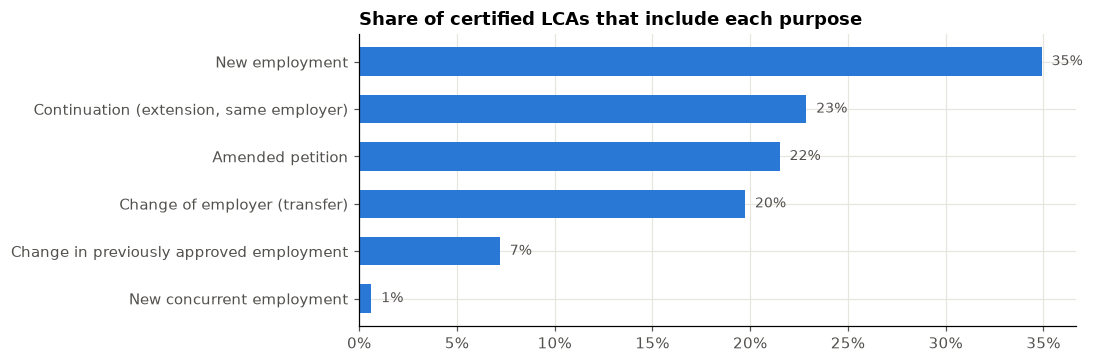

In [25]:
PURPOSES = {
    "NEW_EMPLOYMENT": "New employment",
    "CONTINUED_EMPLOYMENT": "Continuation (extension, same employer)",
    "CHANGE_PREVIOUS_EMPLOYMENT": "Change in previously approved employment",
    "NEW_CONCURRENT_EMPLOYMENT": "New concurrent employment",
    "CHANGE_EMPLOYER": "Change of employer (transfer)",
    "AMENDED_PETITION": "Amended petition",
}
purpose = pd.Series({label: (h1b[col] > 0).mean() for col, label in PURPOSES.items()}).sort_values()

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.barh(purpose.index, purpose.values * 100, color=BLUE, height=0.6)
for y, v in enumerate(purpose.values):
    ax.text(v * 100 + 0.5, y, f"{v:.0%}", va="center", fontsize=9, color="#52514e")
ax.xaxis.set_major_formatter(pct)
ax.set_title("Share of certified LCAs that include each purpose")
plt.tight_layout()
plt.show()

Only about **one third of LCAs include new employment**. The rest concern people already in H-1B status: extensions,
transfers to a new employer, and amendments (often needed when a worker's worksite moves, which became common with
remote work). LCA volume therefore overstates new inflow by a wide margin.

The mix also differs a lot by employer. Among the largest filers, the share of LCAs for new employment ranges
from about 10% (TCS, Apple) to over 50% (Google, Intel, Qualcomm, Wipro):

In [26]:
new_share = (h1b[h1b["EMPLOYER"].isin(per_employer.head(20).index)]
             .groupby("EMPLOYER")["NEW_EMPLOYMENT"].apply(lambda s: (s > 0).mean())
             .sort_values(ascending=False))
new_share.rename("share including new employment").to_frame().style.format("{:.0%}")

,share including new employment
EMPLOYER,
"QUALCOMM TECHNOLOGIES, INC.",67%
INTEL CORPORATION,59%
WIPRO LIMITED,53%
GOOGLE LLC,52%
ERNST & YOUNG U.S. LLP,46%
IBM CORPORATION,41%
HCL AMERICA INC,37%
AMAZON.COM SERVICES LLC,35%
"AMAZON WEB SERVICES, INC.",35%


## 11. The smaller visa classes: E-3 and H-1B1

E-3 (Australia) and H-1B1 (Chile, Singapore) are treaty-based cousins of H-1B. They are not subject to the H-1B lottery
and have their own annual allocations, which in practice are under-used.

In [27]:
others = df[(df["VISA_CLASS"] != "H-1B") & (df["CASE_STATUS"] == "Certified")]
rows = []
for visa, g in others.groupby("VISA_CLASS"):
    top3 = g["SOC_TITLE"].value_counts().head(3)
    rows.append({
        "visa_class": visa,
        "certified_lcas": len(g),
        "median_wage": g["ANNUAL_WAGE"].median(),
        "software_dev_share": (g["SOC_TITLE"] == "Software Developers").mean(),
        "top_3_occupations": "; ".join(f"{k} ({v})" for k, v in top3.items()),
    })
rows.append({"visa_class": "H-1B (for comparison)", "certified_lcas": len(h1b),
             "median_wage": h1b["ANNUAL_WAGE"].median(),
             "software_dev_share": (h1b["SOC_TITLE"] == "Software Developers").mean(),
             "top_3_occupations": "; ".join(f"{k} ({v:,})" for k, v in soc.head(3).items())})
pd.DataFrame(rows).set_index("visa_class").style.format(
    {"certified_lcas": "{:,}", "median_wage": "${:,.0f}", "software_dev_share": "{:.0%}"})

,certified_lcas,median_wage,software_dev_share,top_3_occupations
visa_class,,,,
E-3 Australian,"9,058","$140,000",11%,Software Developers (1018); General and Operations Managers (486); Marketing Managers (456)
H-1B1 Chile,"1,989","$85,000",9%,Software Developers (170); Agricultural Inspectors (129); General and Operations Managers (126)
H-1B1 Singapore,"1,391","$131,300",21%,Software Developers (297); Financial and Investment Analysts (108); Market Research Analysts and Marketing Specialists (65)
H-1B (for comparison),"485,508","$110,000",35%,"Software Developers (169,612); Computer Systems Analysts (28,074); Computer Systems Engineers/Architects (23,280)"


The treaty visas have a **more varied occupational mix** than H-1B. Software is still the top occupation, but at a much
smaller share, with managers, financial analysts and (for Chile) agricultural and other occupations appearing near the top.
E-3, the largest of the three, has a median offer above H-1B's.

## 12. Summary of findings

1. **The raw quarterly files double-count.** About 100k cases (≈18%) appear in two files, mostly Q1 decisions re-published
   in Q2. After de-duplication there are 543,580 cases, of which 485,508 are certified H-1B LCAs.
2. **Certification is fast and near-automatic.** Certified cases are decided in 5–10 days (median 7). Under 0.5% of H-1B LCAs are denied.
3. **The calendar follows the cap lottery.** Decisions peak March–June, and 23% of all LCAs request a job start on 1 October 2023.
4. **Demand is concentrated but long-tailed.** The top 1% of ~54k employers file half of LCAs, while about half of employers file just one.
5. **It is mostly a tech programme.** Two thirds of LCAs are computer/math occupations, and 35% are "Software Developers".
6. **Location matters as much as title.** Median offers for software developers range from ~\$99k (MI) to ~\$164k (CA).
7. **Level II is the default classification** (45% of LCAs), and over a third of LCAs list an offer identical to the prevailing wage.
8. **Business model is the biggest divider.** H-1B-dependent employers (mainly IT services) classify about two thirds of jobs at Level II,
   have a median premium of zero, and offer ~\$20k less at the median. Non-dependent employers spread across all levels with a median ~10% premium.
   Some well-paying firms also list "offer = prevailing wage" on nearly every filing, so that metric needs care.
9. **Most LCAs are not new hires.** Only about a third include new employment; the rest are extensions, transfers and amendments.

### Caveats

* **LCAs ≠ H-1B workers.** These are attestations, not approved petitions or issued visas. Many certified LCAs are never used,
  and one worker can have several.
* **Offered ≠ paid.** The wage is what the form states, and for ranged offers only the bottom of the range is used.
* **Employer names** are lightly normalised. Related legal entities are counted separately.
* **Self-reported flags** (H-1B dependence, wage level) are employer attestations and are not verified at this stage.
* All findings are descriptive. Nothing here establishes cause, e.g. *why* a state pays more.